# K-means clustering

In this notebook, I will use K means clustering to analyse chess positions and attempt to determine the relationship between openings, middlegames and endgames. I will analyse the chances of a White or Black winning, or a draw, at each stage of the game. I will use a heatmap of the clusters to determine the amount of positions at each point of the graph.

For all graphs below, FullMoves refers to moves made since the beginning of the game, a positive evaluation means that White has an advantage, and a negative evaluation means that Black has an advantage. Any evaluation of +-150 is a forced mate.

First, import the CSV and initialise constants:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

# CONSTANTS
# Changing CSV_ROWS or SEED may result in clusters being named inappropriately, as names are static and not dynamically acquired from the clusters themselves
CSV_ROWS = 1_000_000
SEED = 67
SILHOUETTE_SAMPLE_SIZE = 10_000

print("Imports successful")
csv = pd.read_csv('chessData_formatted.csv', nrows=CSV_ROWS)
print("Read CSV successful")

Imports successful
Read CSV successful


### Display Graph

This helper function displays the k-means clustering graph.

In [2]:
def display_graph(data, y_kmeans, labels):
    plt.figure(figsize=[9,5])
    scatter = plt.scatter(data[:, 0], data[:, 1], s=10, c=y_kmeans, cmap="viridis")
    handles, _ = scatter.legend_elements()
    plt.legend(handles=handles, labels=labels, title="Clusters", loc="upper right", frameon=True, framealpha=1, facecolor="white", edgecolor="black")
    plt.xlabel('Full Moves')
    plt.ylabel('Evaluation')
    plt.title('K-Means Clustering')
    plt.xlim(0)
    plt.show()

## Basic K-means Clustering

A k-means clustering analysis has been run on the data. The data has been clustered into 5 clusters:
- Opening
- Middlegame
- Endgame
- Mate for White
- Mate for Black

Mate for White/Black are considered outliers and are clustered separately to the phases of the game to not skew the main clusters of the graph.

The opening has been clustered as all moves before ~25 full moves. However, in a real chess game, the opening usually ends after 5-10 full moves, usually when a player's pieces have been developed and the king is safe. Otherwise, the clusters are accurate with the main phases of the game. Another observation is that usually, the opening of a game is fairly balanced in evaluation. Most chess players tend to play "Book moves", which are opening sequences that are almost always even for both players, and are memorised by higher rated players. There are some outliers in the opening sequence, that is mainly due to opening "traps", or blunders by one player resulting in a huge advantage for the other player.

The middlegame is clustered as all position between ~25 and ~50 full moves, which I would agree is an accurate representation of the middlegame. Many positions at all evaluations can be found here, as the main tactical and positional gameplay of chess is found here. Without a heatmap, it is not possible from this graph alone to determine the proportion of even positions, and positions with an advantage.

The endgame is clustered as all positions after ~50 full moves, which I also agree is an accurate representation, however some endgames can start much earlier. The endgame tends to be the longest in some games, as many moves are sometimes required to make little progress. The longer a game goes on (>100 moves), the more likely it is that the game ends in a draw. This happens because, based on my experience of chess, most winning games are won long before the 100 move threshold. Very long games tend to end in a draw either because of inexperienced players unable to secure victory, or one or both players playing for a draw instead of a victory as it's sometimes more achievable. Sometimes a game ends in a stalemate, or draw by 50 move rule, or draw by insufficient material.

At all stages of the game, there are positions where one player has blundered a forced checkmate. The fastest possible mate is called the [fool's mate](https://en.wikipedia.org/wiki/Fool%27s_mate), and a mate position can happen at any point of the game.

The silhouette score of the output is ~0.51, meaning that the clusters are reasonably separated but contain some overlaps at their borders. There are some stray mis-clustered points, due to the points being closer to the centroid of the "Mate" clusters than to the "Game phase" clusters. This can be fixed either by re-weighing the clusters and preventing them from being miscoloured, or by removing mate evaluations entirely from the dataset and re-clustering them again.

In general, the K-means clustering algorithm has managed to cluster the phases of a chess game reasonably well, given no prior knowledge of what a chess game actually is.

Silhouette Score:  0.5110590957427922


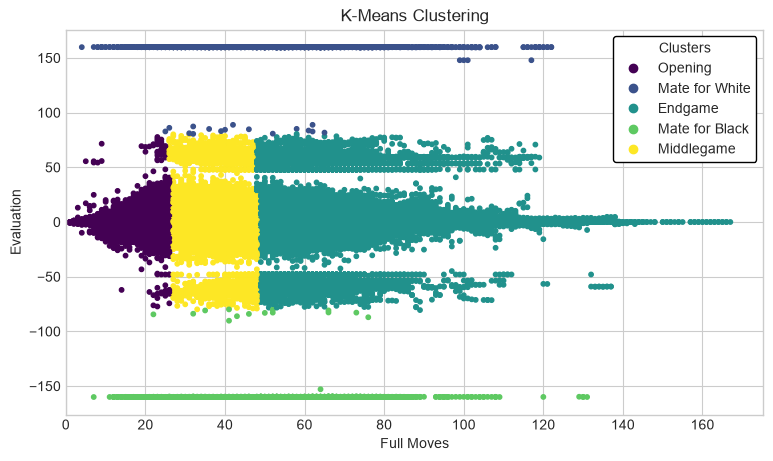

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

fullMoves = csv["fullMoves"].values
evaluation = csv["Evaluation"].values / 100

kmeans = KMeans(n_clusters=5, random_state=SEED)
data = np.column_stack((fullMoves, evaluation))
kmeans.fit(data)
y_kmeans = kmeans.predict(data)

score = silhouette_score(data, y_kmeans, sample_size=SILHOUETTE_SAMPLE_SIZE, random_state=SEED)
print("Silhouette Score: ", score)

display_graph(data, y_kmeans, ["Opening", "Mate for White", "Endgame", "Mate for Black", "Middlegame"])

# Capped clustering

To remove the mis-clustered points from the graph above, I have decided to remove all points above +-100 evaluation, which removes any outliers and forced checkmate positions. The 3 phases of the game remain clustered similarly to the graph above. The silhouette score is also similar.

Silhouette score:  0.5067012316730681


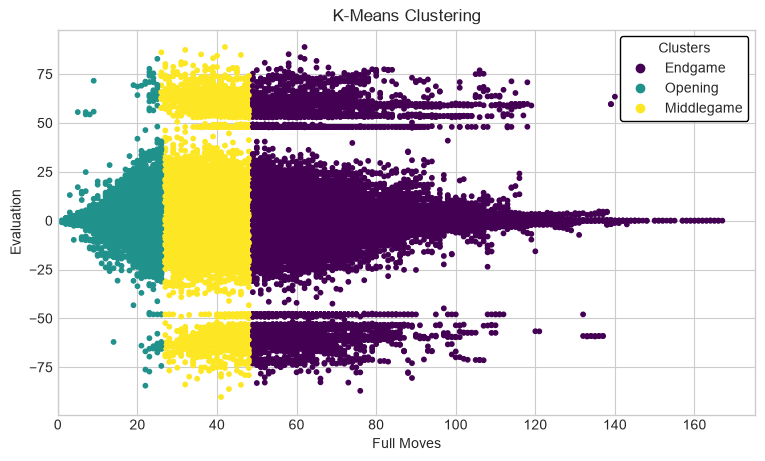

In [4]:
mask = np.abs(data[:, 1]) < 100
cappedData = data[mask]

capped_kmeans = KMeans(n_clusters=3, random_state=SEED)
capped_kmeans.fit(cappedData)
capped_y_kmeans = capped_kmeans.predict(cappedData)

score2 = silhouette_score(cappedData, capped_y_kmeans, sample_size=SILHOUETTE_SAMPLE_SIZE, random_state=SEED)
print("Silhouette score: ", score2)

display_graph(cappedData, capped_y_kmeans, ["Endgame", "Opening", "Middlegame"])

# Heatmap

The K-means clusters above cluster 1,000,000 chess positions from the dataset. However, as mentioned above, there is no possible way to tell do more equal positions exist, or do more winning positions exist for either side, as the dots form a solid colour. The solution for this is a log scale heatmap.

A heatmap can tell us visually how many positions are actually in each area of the graph. A log scale heatmap is used, otherwise the heatmap would be concentrated on a single line near the centre, where the vast majority of positions are found. The heatmap also tells us that many points are in fact just singular points, rather than a trend of many points in some area.

The heatmap also tells us that the majority of forced mate positions are in the middlegame, rather than spread evenly. There is very few in the opening, and the number of forced checkmate positions lessens as the game progresses. Finally, the heatmap tells us that the vast majority of games end within 100 moves, with a minority of games going beyond that.

There are 2 heatmaps below, corresponding to the 2 K-means-clustered graphs above.

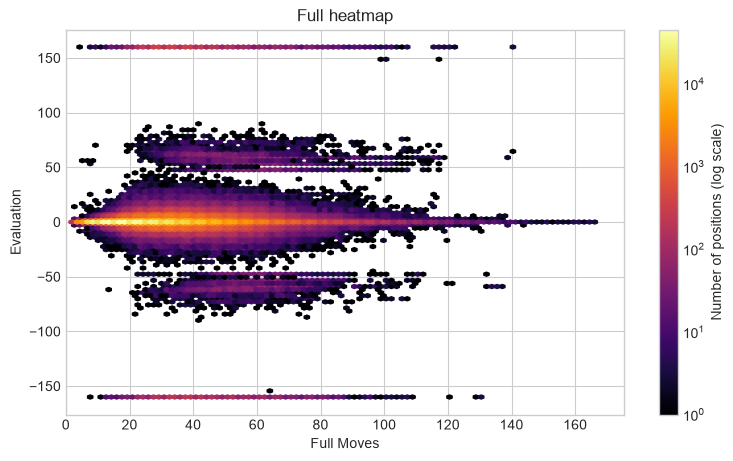

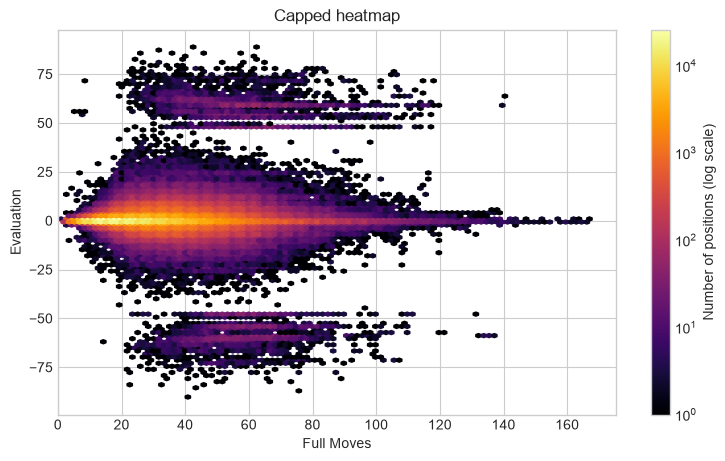

In [5]:
def show_heat_map(d, title):
    plt.figure(figsize=[9, 5])
    hb = plt.hexbin(d[:, 0], d[:, 1], cmap="inferno", bins="log")
    plt.colorbar(hb, label="Number of positions (log scale)")
    plt.xlabel("Full Moves")
    plt.ylabel("Evaluation")
    plt.title(title)
    plt.xlim(0)
    plt.show()

show_heat_map(data, "Full heatmap")
show_heat_map(cappedData, "Capped heatmap")

# Who has a higher chance of winning?

The clustered data above looks evenly spread between the White and Black players. Both players seem to have an equal chance of winning or losing. We can prove this by running a simple linear regression on the data. The graph shows that there is a higher chance for White to win than Black, White has an advantage of 2-3 pawns after 160 moves. To confirm this, the model was run on intervals of 10 moves, printed below the graph. After 70 moves, White only has a 1 pawn advantage on average. White starts with an advantage of 0.34 pawns on move 1, and Stockfish on [Chess.com](https://chess.com) evaluates to +0.6 on White's first move. Therefore, White's slight advantage is negligible, and does not mean that White is proven to win more times than Black.

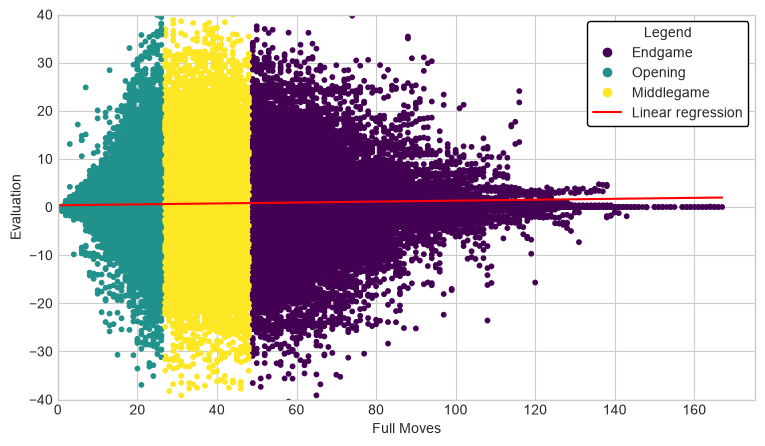

Full Moves: 0, Evaluation: 0.36
Full Moves: 10, Evaluation: 0.45
Full Moves: 20, Evaluation: 0.55
Full Moves: 30, Evaluation: 0.65
Full Moves: 40, Evaluation: 0.74
Full Moves: 50, Evaluation: 0.84
Full Moves: 60, Evaluation: 0.94
Full Moves: 70, Evaluation: 1.03
Full Moves: 80, Evaluation: 1.13
Full Moves: 90, Evaluation: 1.23
Full Moves: 100, Evaluation: 1.32


In [6]:
from sklearn.linear_model import LinearRegression

model = LinearRegression(fit_intercept=True)

x = data[:, 0]
y = data[:, 1]
model.fit(x[:, np.newaxis], y)
xfit = np.linspace(0, x.max())
yfit = model.predict(xfit[:, np.newaxis])

plt.figure(figsize=[9, 5])
scatter = plt.scatter(cappedData[:, 0], cappedData[:, 1], s=10, c=capped_y_kmeans, cmap="viridis")
cluster_handles, _ = scatter.legend_elements()

line, = plt.plot(xfit, yfit, color="red", label="Linear regression")

plt.legend(handles=cluster_handles + [line],
           labels=["Endgame", "Opening", "Middlegame", "Linear regression"],
           title="Legend",
           loc="upper right",
           frameon=True,
           framealpha=1,
           facecolor="white",
           edgecolor="black"
           )

plt.xlabel('Full Moves')
plt.ylabel('Evaluation')
plt.xlim(0)
plt.ylim(-40, 40)
plt.show()

xvals = np.array([0,10,20,30,40,50,60,70,80,90,100])
yvals = model.predict(xvals[:, np.newaxis])
for xv, yv in zip(xvals, yvals):
    print(f"Full Moves: {xv}, Evaluation: {round(yv, 2)}")

# Conclusion

With K-means clustering, the phases of a chess game can be identified given just the move count since the beginning of the game and the evaluation. K-means clustering is an unsupervised learning algorithm. The clusters generated are reasonably close to what chess players consider to be the phases of the game, considering that this algorithm has no prior knowledge of chess, chess positions or evaluations.

K-means clustering is a simple yet effective way to cluster a set of data points into distinguishable clusters. In the first graph, there is a few points mistakenly clustered in the wrong cluster, but with more advanced algorithms this can be fixed. Pruning the data to remove outliers (in this case, forced checkmate positions), can also help with the clustering.

### Heatmaps

The clusters are good enough to display the phases of the game, however trying to determine the number of positions at each point is impossible, as the amount of points combine into a solid colour. A heatmap was generated to display this information.

The heatmap now shows that the vast majority of chess positions, and therefore games, are even or within a +-5 advantage. There are few positions that have a huge advantage in one or the other direction. The heatmap also tells us that forced checkmate positions are mainly found in the middlegame and endgame, and rarely in the opening. A significant factor of the openings being evenly evaluated is because the opening of chess is solved in theory, and most players play some sort of learned or memorised opening that is even for both players. Lastly, the heatmap tells us that the majority of games last 60 moves or fewer.


### Who has a higher chance of winning?

The heatmaps alone tell us that both players have an equal chance of winning, losing or drawing at any stage of the game. However, a visual conclusion is not enough to determine this. After running the data through a simple linear regression model, it shows that White has a very slight advantage at all stages of the game. White starts with a 0.34 pawn advantage, and by move 60 where most games end, White's advantage is on average just 0.94 pawns. Such a small advantage is practically negligible for human players. Therefore, it can be concluded that, for human players, both White and Black have an equal chance of winning, losing, or ending in a draw.